# Lab 1 — Supervised Baselines + Validation + Leakage Checks

**Goal:** build a defensible supervised baseline and practice a clean validation workflow.

You will:
- build a `Pipeline` for preprocessing + model
- compare a simple baseline vs a stronger model
- choose task metrics correctly (classification + optional regression)
- demonstrate a common leakage mistake and fix it


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)


## 1) Load data

In [2]:
df = pd.read_csv("./data/ecommerce_sessions.csv")
df.head()


,session_id,country,device_type,traffic_source,session_minutes,pages_viewed,avg_scroll_depth,items_added_to_cart,prior_visits_30d,purchase,spend_usd,event_time
0,S100000,IN,mobile,search,4.516530,7,0.514905,1,4,1,54.57,2025-10-03 17:24:00
1,S100001,TR,desktop,search,0.962363,5,0.473726,4,0,1,58.80,2025-10-15 00:44:00
2,S100002,US,mobile,social,6.869928,7,0.700772,1,2,0,0.00,2025-10-05 22:51:00
3,S100003,DE,desktop,search,5.087378,8,0.527164,0,2,1,47.91,2025-10-14 16:58:00
4,S100004,KZ,desktop,direct,5.179733,7,0.636064,0,3,0,0.00,2025-09-05 05:44:00


## 2) Choose target and features

Default target: `purchase` (binary classification).

**Important:** Drop identifiers. Avoid using `event_time` unless you handle it carefully.


In [3]:
target = "purchase"
drop_cols = ["session_id", "spend_usd"]  # we keep purchase as target, drop spend for now
X = df.drop(columns=[target] + drop_cols)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

X_train.shape, X_test.shape


((1350, 9), (450, 9))

## 3) Build preprocessing + baseline model (Logistic Regression)

**TODO:** Run this, then report Accuracy + F1 + ROC-AUC.


In [4]:
numeric_features = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]),
         numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
         categorical_features),
    ]
)

baseline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=500))
])

baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
y_proba = baseline.predict_proba(X_test)[:,1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}
{k: round(v, 3) for k,v in metrics.items()}


/var/folders/hh/038yvty53_j0vqjm7w3g3j9c0000gn/T/ipykernel_98520/1321020064.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()


{'accuracy': 0.616,
 'precision': 0.627,
 'recall': 0.727,
 'f1': 0.673,
 'roc_auc': 0.647}

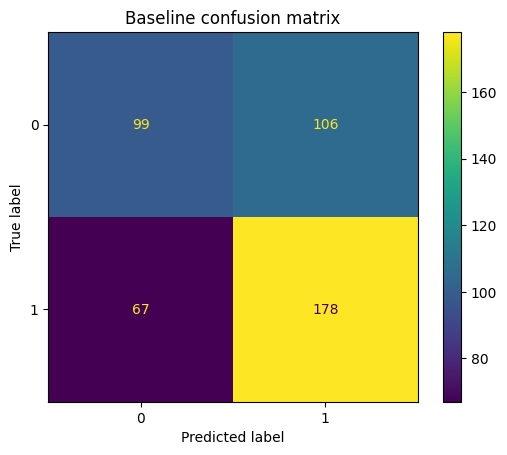

In [5]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Baseline confusion matrix")
plt.show()


## 4) Stronger model: Random Forest

**TODO:** Compare to baseline. Which metric improved and why?


In [6]:
rf = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=250, random_state=42, n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf.fit(X_train, y_train)
y_pred2 = rf.predict(X_test)
y_proba2 = rf.predict_proba(X_test)[:,1]

metrics2 = {
    "accuracy": accuracy_score(y_test, y_pred2),
    "precision": precision_score(y_test, y_pred2),
    "recall": recall_score(y_test, y_pred2),
    "f1": f1_score(y_test, y_pred2),
    "roc_auc": roc_auc_score(y_test, y_proba2),
}
{k: round(v, 3) for k,v in metrics2.items()}


{'accuracy': 0.544,
 'precision': 0.544,
 'recall': 1.0,
 'f1': 0.705,
 'roc_auc': 0.633}

## 5) Cross-validation (optional but recommended)

**TODO:** Estimate F1 using 5-fold stratified CV for the baseline model.


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(baseline, X, y, cv=cv, scoring="f1")
scores.mean(), scores.std()


(np.float64(0.6478220147550056), np.float64(0.015212238824428972))

## 6) Leakage demo (common mistake)

We'll create a *bad* feature that uses the label. This will artificially inflate performance.

**Task:**
- Observe the (fake) improvement.
- Remove the leaking feature and confirm performance returns to normal.


In [8]:
X_leaky = X.copy()
X_leaky["leak_purchase_copy"] = y  # this is illegal leakage

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leaky, y, test_size=0.25, random_state=42, stratify=y
)

baseline_leaky = Pipeline(steps=[("prep", ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]),
         X_train_l.select_dtypes(include=["int64","float64"]).columns.tolist()),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
         X_train_l.select_dtypes(include=["object"]).columns.tolist()),
    ]
)), ("clf", LogisticRegression(max_iter=500))])

baseline_leaky.fit(X_train_l, y_train_l)
y_pred_l = baseline_leaky.predict(X_test_l)
y_proba_l = baseline_leaky.predict_proba(X_test_l)[:,1]

{
    "f1": round(f1_score(y_test_l, y_pred_l), 3),
    "roc_auc": round(roc_auc_score(y_test_l, y_proba_l), 3)
}


/var/folders/hh/038yvty53_j0vqjm7w3g3j9c0000gn/T/ipykernel_98520/12759598.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train_l.select_dtypes(include=["object"]).columns.tolist()),


{'f1': 1.0, 'roc_auc': 1.0}

## 7) Deliverable: short memo outline (for defense)

Use this structure:

1) Target + stakeholder question
2) Data + feature choices (and what you excluded)
3) Baseline model + metrics
4) Stronger model + what improved
5) Validation (split or CV) + why it's reasonable
6) Leakage risk: what you checked
7) Next step: one improvement you would test
